## 1. Load the Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset is loaded directly from the internet (no upload needed)
url = "https://huggingface.co/datasets/mdmoin19/Banking-dataset/raw/main/loan_approval_dataset.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")

# Clean column names and text values
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

Dataset loaded successfully!


In [ ]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [ ]:
df.shape

(4269, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [ ]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


## 2. Data Cleaning

In [ ]:
# Check missing values
print("Missing values:")
df.isnull().sum()

Missing values:


,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


In [ ]:
# Remove unnecessary ID column
if "loan_id" in df.columns:
    df = df.drop("loan_id", axis=1)

In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 0


### Convert target column into numbers
Approved = 1, Rejected = 0

In [ ]:
df["loan_status"] = df["loan_status"].map({"Approved": 1, "Rejected": 0})

print(df["loan_status"].value_counts())

loan_status
1    2656
0    1613
Name: count, dtype: int64


## 3. Statistical Summary

In [ ]:
income = df["income_annum"]

print("Mean               :", income.mean())
print("Median             :", income.median())
print("Mode               :", income.mode()[0])


Mean               : 5059123.9166081045
Median             : 5100000.0
Mode               : 7000000


## 4. Exploratory Data Analysis (EDA)

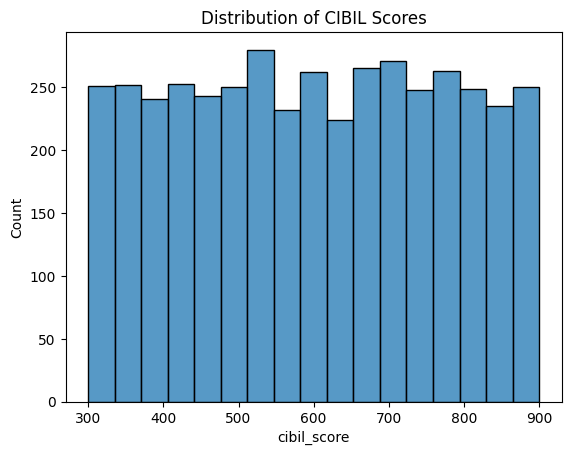

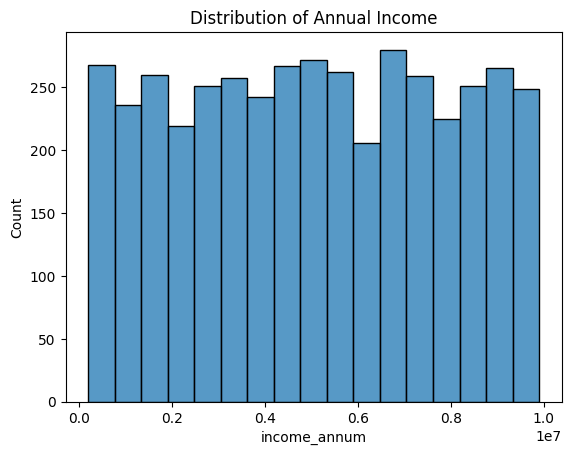

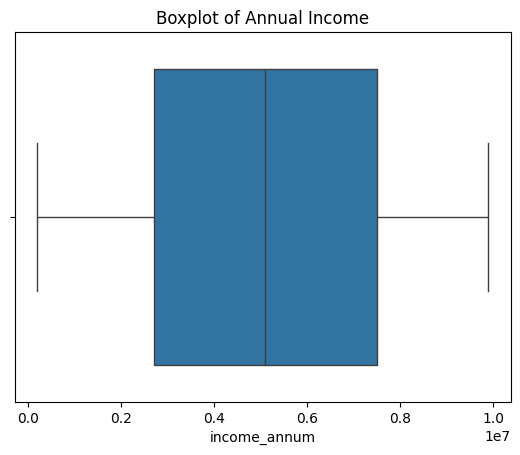

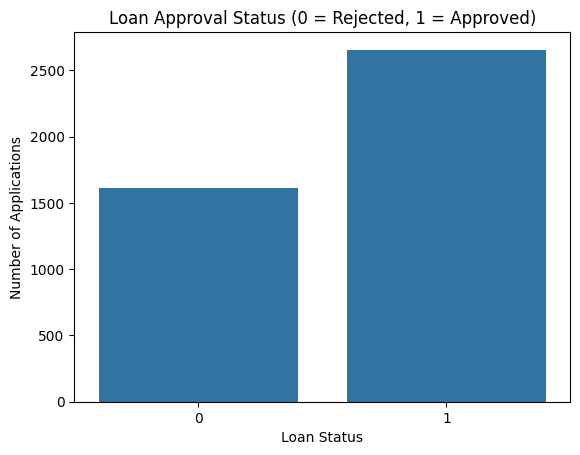

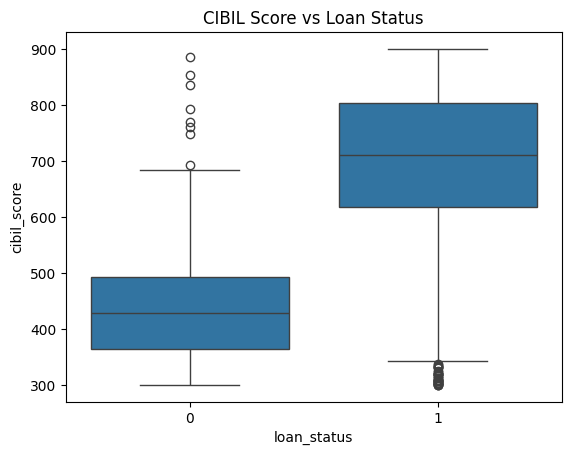

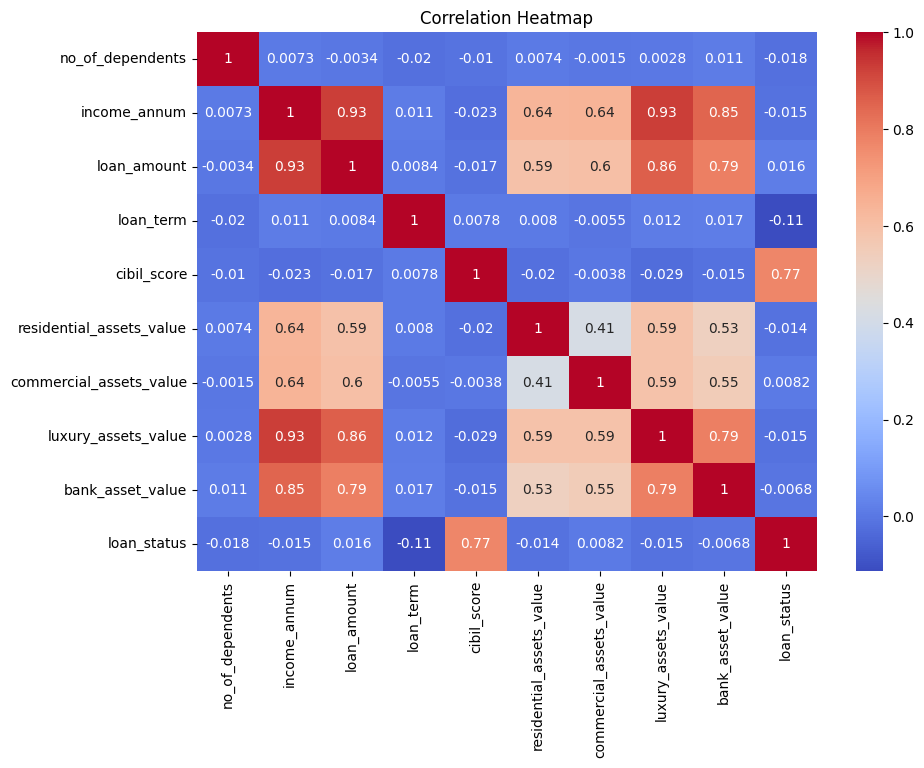

In [ ]:
# 1. Histplot: Distribution of CIBIL scores
sns.histplot(data=df, x="cibil_score")
plt.title("Distribution of CIBIL Scores")
plt.show()

# 2. Distribution plot: Distribution of annual income
sns.histplot(data=df, x="income_annum")
plt.title("Distribution of Annual Income")
plt.show()

# 3. Boxplot: Check outliers in annual income
sns.boxplot(x=df["income_annum"])
plt.title("Boxplot of Annual Income")
plt.show()

# 4. Bar plot: Number of approved and rejected loans
sns.countplot(data=df, x="loan_status")
plt.title("Loan Approval Status (0 = Rejected, 1 = Approved)")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.show()

# 5. Boxplot: CIBIL score vs loan status
sns.boxplot(data=df, x="loan_status", y="cibil_score")
plt.title("CIBIL Score vs Loan Status")
plt.show()

# 6. Heatmap: Correlation between numerical features
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    cmap="coolwarm", annot=True,
)
plt.title("Correlation Heatmap")
plt.show()

## 5. Outlier Detection (IQR Method)

In [ ]:
Q1 = df["income_annum"].quantile(0.25)
Q3 = df["income_annum"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

outliers = df[(df["income_annum"] < lower) | (df["income_annum"] > upper)]
print("Number of outliers:", len(outliers))

# Remove outliers
df = df[(df["income_annum"] >= lower) & (df["income_annum"] <= upper)]
print("Shape after removing outliers:", df.shape)

Lower limit: -4500000.0
Upper limit: 14700000.0
Number of outliers: 0
Shape after removing outliers: (4269, 12)


## 6. Encoding, Train-Test Split and Scaling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

# Convert categorical features into numerical columns
X = pd.get_dummies(X, dtype=int)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing completed successfully!")

Training data: (3415, 13)
Testing data: (854, 13)
Preprocessing completed successfully!


## 7. Summary of Pre-processing Steps

- Loaded the dataset and cleaned column names and text values.
- Checked missing values and removed the unnecessary `loan_id` column.
- Removed duplicate rows.
- Converted the target `loan_status` into numbers (Approved = 1, Rejected = 0).
- Studied the data using statistics and graphs (EDA).
- Detected and removed outliers using the IQR method.
- Converted categorical columns into numbers using `get_dummies`.
- Split the data into training (80%) and testing (20%) sets.
- Scaled the features using `StandardScaler`.

The data is now ready for model training.

## 8. Model Training (Logistic Regression)

In [ ]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression
model = LogisticRegression()

# Train the model
model.fit(X_train_scaled, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## 9. Prediction

In [ ]:
y_pred = model.predict(X_test_scaled)
y_pred

array([0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0,

In [ ]:
# Compare actual and predicted values (first 10)
comparison = pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10]})
comparison

,Actual,Predicted
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,1,1
7,0,0
8,1,1
9,0,0


## 10. Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[274,  44],
       [ 38, 498]])

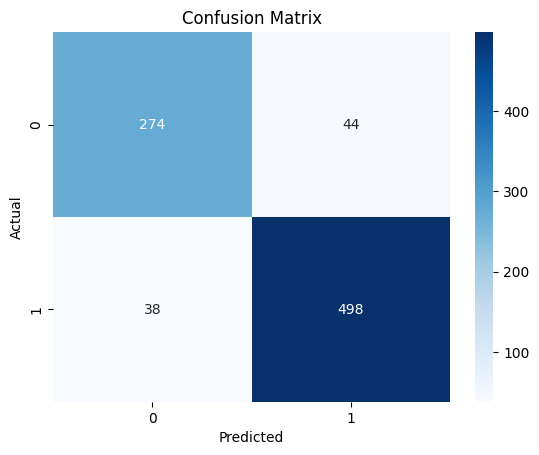

In [ ]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## 11. Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy(%):", accuracy * 100)

Accuracy: 0.9039812646370023
Accuracy(%): 90.39812646370024


## 12. Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

              precision    recall  f1-score   support

    Rejected       0.88      0.86      0.87       318
    Approved       0.92      0.93      0.92       536

    accuracy                           0.90       854
   macro avg       0.90      0.90      0.90       854
weighted avg       0.90      0.90      0.90       854



## 13. Credit Risk Prediction for a New Applicant

In [ ]:
# Details of a new applicant (same columns as the training data)
new_applicant = pd.DataFrame({
    'no_of_dependents': [2],
    'income_annum': [6000000],
    'loan_amount': [15000000],
    'loan_term': [12],
    'cibil_score': [750],
    'residential_assets_value': [5000000],
    'commercial_assets_value': [3000000],
    'luxury_assets_value': [10000000],
    'bank_asset_value': [4000000],
    'education_Graduate': [1],
    'education_Not Graduate': [0],
    'self_employed_No': [1],
    'self_employed_Yes': [0]
})

# Keep the columns in the same order as the training data
new_applicant = new_applicant[X.columns]

# Scale and predict
new_scaled = scaler.transform(new_applicant)
result = model.predict(new_scaled)
probability = model.predict_proba(new_scaled)[0][1]

if result[0] == 1:
    print("Loan Status: Approved")
else:
    print("Loan Status: Rejected")

print("Approval Probability(%):", probability * 100)

Loan Status: Approved
Approval Probability(%): 98.7508508903819


In [ ]:
# Credit Risk Level based on approval probability
if probability >= 0.70:
    print("Credit Risk: Low Risk")
elif probability >= 0.40:
    print("Credit Risk: Medium Risk")
else:
    print("Credit Risk: High Risk")

Credit Risk: Low Risk


## 14. Conclusion

- A Logistic Regression model was trained on the preprocessed loan data.
- The model predicted the loan status (Approved / Rejected) for the test data.
- The performance was checked using the confusion matrix, accuracy and classification report.
- For a new applicant, the model gives the loan decision and the approval probability, which is used to find the credit risk level (Low / Medium / High).